<p class="hz-kicker">Applied case · Toolkit</p>

# Case toolkit

One notebook that runs the whole analysis once you tell it which data to use and what to predict: it audits and cleans the data, draws the patterns, trains five models, compares them, and explains the best one.

<ul class="hz-lesson-meta"><li>Regression or classification</li><li>Runs in your browser or Colab</li><li>No coding from scratch</li></ul>

**How to use it.** Open the notebook in Colab with the **Open in Colab** button and save a copy in your team's Drive ([Colab guide](https://hizocar.github.io/mba-business-analytics-1/colab/)). Then:

1. Change only the cells marked **✏️**: the settings at the top, the cleaning decisions in section 03, and the number of charts in section 04.
2. Run every cell from top to bottom (in Colab: *Runtime → Run all*).
3. Under each section, write what the result means for your business in the **✍️ Your interpretation** cell. That text is your deliverable ([case brief and rubric](https://hizocar.github.io/mba-business-analytics-1/case/case/)).

The defaults run Case A, TalentCo salaries. Each section links to the week where the idea was taught.

Run this cell first. You don't need to read it: it loads the tools and defines the helpers the sections below use.

In [1]:
# Setup: run this cell first. You don't need to read it.
import re, difflib, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, KFold, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                              HistGradientBoostingRegressor, HistGradientBoostingClassifier)
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn import metrics as skm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})
DATA = "https://raw.githubusercontent.com/hizocar/mba-business-analytics-1/main/docs/datasets/"
MISSING_WORDS = {"", "nan", "none", "null", "na", "n/a", "?", "-", "missing"}
DATE_RE = r"^\s*(\d{4}-\d{1,2}-\d{1,2}|\d{1,2}/\d{1,2}/\d{2,4})"


def fmt(x, d=None):
    """A number as readable text: 12,345 or 3.14."""
    if x is None or pd.isna(x):
        return "-"
    if d is None:
        d = 0 if abs(x) >= 100 else 1 if abs(x) >= 10 else 2
    return f"{x:,.{d}f}"


def label_key(v):
    """Lower case, no accents, letters and digits only: ' Viña del Mar' -> 'vinadelmar'."""
    s = unicodedata.normalize("NFKD", str(v)).encode("ascii", "ignore").decode()
    return re.sub(r"[^0-9a-z]", "", s.lower())


def is_text(s):
    return not pd.api.types.is_numeric_dtype(s) and not pd.api.types.is_datetime64_any_dtype(s)


def missing_words(s):
    """True where a text cell says 'nan', 'N/A', '?'... instead of being empty."""
    if not is_text(s):
        return pd.Series(False, index=s.index)
    return s.notna() & s.astype(str).str.strip().str.lower().isin(MISSING_WORDS)


def as_number(s):
    """Text such as '12.5%' or '1,200' read as a number (NaN when it is not one)."""
    return pd.to_numeric(s.astype(str).str.replace(r"[%,\s]", "", regex=True), errors="coerce")


def kind_of_text(s):
    """'date', 'number' or 'label' for a text column."""
    v = s[s.notna() & ~missing_words(s)].astype(str)
    if len(v) == 0:
        return "label"
    if v.str.match(DATE_RE).mean() >= 0.9:
        return "date"
    if as_number(v).notna().mean() >= 0.9:
        return "number"
    return "label"


def canonical_map(s):
    """Map every spelling to the most common spelling with the same key."""
    vc = s.dropna().astype(str).str.strip().value_counts()
    best = {}
    for label in vc.index:
        best.setdefault(label_key(label), label)
    return best


def audit(df, target, skip=()):
    """A table of data-quality findings with a suggested decision for each."""
    rows = []
    def add(problem, col, n, example, decision):
        rows.append({"Problem": problem, "Column": col, "Rows": int(n), "Example": example, "Suggested decision": decision})
    d = int(df.duplicated().sum())
    if d:
        add("Duplicate rows", "(all)", d, "exact copies of another row", "Drop the copies: DROP_DUPLICATES = True")
    for c in df.columns:
        s, words = df[c], missing_words(df[c])
        miss = int(s.isna().sum() + words.sum())
        if miss:
            ex = f"{miss / len(df):.1%} of rows" + (f", {int(words.sum())} written as text, e.g. '{s[words].iloc[0]}'" if words.any() else "")
            dec = ("Drop these rows: a row without the answer cannot teach or test" if c == target
                   else "Consider dropping the column (DROP_COLUMNS)" if miss > 0.4 * len(df)
                   else "Fill them: FILL_MISSING = \"median\"")
            add("Missing values", c, miss, ex, dec)
        if c in skip:
            continue
        v = s[s.notna() & ~words]
        if v.nunique() <= 1:
            add("Only one value", c, len(v), f"always '{v.iloc[0] if len(v) else '-'}'", "Drop it: it cannot explain differences")
            continue
        if not is_text(s):
            v = v.astype(float)
            neg = int((v < 0).sum())
            if 0 < neg <= 0.05 * len(v):
                add("Negative values", c, neg, f"min {fmt(v.min())}, while most rows are positive",
                    f"Probably errors: add a rule, e.g. \"{c}\": (0, None)")
            q1, q3 = v.quantile([0.25, 0.75])
            lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
            out = int(((v < lo) | (v > hi)).sum())
            if q3 > q1 and v.nunique() > 10 and out:
                add("Extreme values", c, out, f"outside {fmt(lo)} to {fmt(hi)}; min {fmt(v.min())}, max {fmt(v.max())}",
                    "If impossible, add a rule to IMPOSSIBLE_VALUES; if real, keep them")
            continue
        kind, v = kind_of_text(s), v.astype(str)
        if kind == "date":
            add("Dates stored as text", c, len(v), f"e.g. '{v.iloc[0]}'", "Keep the month: DATE_HANDLING = \"month\", or \"drop\"")
            continue
        if kind == "number":
            odd = v[~v.str.match(r"^\s*-?\d+(\.\d+)?\s*\Z")]
            add("Numbers stored as text", c, len(odd) if len(odd) else len(v), f"e.g. '{odd.iloc[0] if len(odd) else v.iloc[0]}'",
                "Converted to numbers automatically in section 03")
            continue
        if v.nunique() > 0.9 * len(v) and len(v) > 50:
            add("Looks like an identifier", c, len(v), f"e.g. '{v.iloc[0]}' ({v.nunique():,} different values)", "Add it to ID_COLUMNS")
            continue
        vc = v.str.strip().value_counts()
        keys = vc.groupby(vc.index.map(label_key))
        bad = keys.filter(lambda g: len(g) > 1)
        if len(bad):
            k0 = label_key(bad.index[0])
            ex = " / ".join(f"'{x}'" for x in vc.index if label_key(x) == k0)
            add("Inconsistent spelling", c, int(bad.sum() - keys.max()[keys.size() > 1].sum()), ex,
                "Merge the spellings: NORMALISE_TEXT = True")
        sizes = keys.sum().sort_values(ascending=False)
        if len(sizes) <= 50:
            for k, n in sizes.items():
                near = [m for m in difflib.get_close_matches(k, sizes.index, n=3, cutoff=0.8) if m != k and sizes[m] > 4 * n]
                if near:
                    add("Possible typo", c, n, f"'{vc[vc.index.map(label_key) == k].index[0]}' looks like '{vc[vc.index.map(label_key) == near[0]].index[0]}'",
                        "Merge them with VALUE_MAP")
    return pd.DataFrame(rows) if rows else pd.DataFrame([{"Problem": "No problems found", "Column": "", "Rows": 0, "Example": "", "Suggested decision": ""}])


def clean(df):
    """Apply the decisions in the cleaning settings and keep a log."""
    log, n0 = [], len(df)
    def note(problem, decision, n):
        log.append({"Problem": problem, "Decision": decision, "Rows affected": n})
    df = df.copy()
    if DROP_DUPLICATES:
        n = int(df.duplicated().sum())
        df = df.drop_duplicates()
        note("Duplicate rows", "Dropped the copies", n)
    gone = [c for c in ID_COLUMNS + DROP_COLUMNS if c in df.columns and c != TARGET]
    if gone:
        df = df.drop(columns=gone)
        note("Identifiers, leakage, irrelevant", "Columns removed: " + ", ".join(gone), "whole column")
    for c in [c for c in df.columns if is_text(df[c])]:
        w = missing_words(df[c])
        if w.any():
            df.loc[w, c] = np.nan
            note(f"{c}: text that means 'missing'", "Treated as missing", int(w.sum()))
        kind = kind_of_text(df[c])
        if kind == "date":
            if DATE_HANDLING == "month":
                m = pd.to_datetime(df[c], errors="coerce").dt.month
                df[c + "_month"] = m.map(lambda x: f"{int(x):02d}" if pd.notna(x) else np.nan)
            df = df.drop(columns=c)
            note(f"{c}: a date stored as text", f"Kept only the month as {c}_month" if DATE_HANDLING == "month" else "Column removed", int(df[c + "_month"].notna().sum()) if DATE_HANDLING == "month" else "whole column")
            continue
        if kind == "number":
            odd = int((~df[c].dropna().astype(str).str.match(r"^\s*-?\d+(\.\d+)?\s*\Z")).sum())
            df[c] = as_number(df[c])
            note(f"{c}: numbers stored as text", "Converted to numbers ('12.5%' becomes 12.5)", odd)
            continue
        old = df[c].copy()
        if NORMALISE_TEXT:
            best = canonical_map(df[c])
            df[c] = df[c].map(lambda v: best[label_key(v)] if pd.notna(v) else v)
            n = int((old.notna() & (old != df[c])).sum())
            if n:
                note(f"{c}: inconsistent spelling", "Merged each label's spellings into the most common one", n)
        if c in VALUE_MAP:
            best = canonical_map(df[c])
            mapping = {label_key(a): best.get(label_key(b), b) for a, b in VALUE_MAP[c].items()}
            before = df[c].copy()
            df[c] = df[c].map(lambda v: mapping.get(label_key(v), v) if pd.notna(v) else v)
            note(f"{c}: labels that mean the same", "Merged: " + ", ".join(f"{a} → {b}" for a, b in VALUE_MAP[c].items()),
                 int((before.notna() & (before != df[c])).sum()))
    if CLASSIFICATION:
        y = df[TARGET]
        df[TARGET] = np.where(y.isna(), np.nan, (y.map(label_key) == label_key(POSITIVE)).astype(float)) if is_text(y) else y
    else:
        df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
    for c, (lo, hi) in IMPOSSIBLE_VALUES.items():
        if c not in df.columns:
            note(f"Rule for {c}", "Skipped: there is no such column", 0)
            continue
        v = pd.to_numeric(df[c], errors="coerce")
        bad = pd.Series(False, index=df.index)
        if lo is not None:
            bad |= v < lo
        if hi is not None:
            bad |= v > hi
        say = lambda v: f"{v:,.0f}" if float(v).is_integer() else f"{v:,}"
        rule = f"{c} outside {say(lo) if lo is not None else 'no minimum'} to {say(hi) if hi is not None else 'no maximum'}"
        if c == TARGET or IMPOSSIBLE_ACTION == "drop":
            df = df[~bad]
            note(f"Impossible values: {rule}", "Rows dropped", int(bad.sum()))
        else:
            df.loc[bad, c] = np.nan
            note(f"Impossible values: {rule}", "Made missing, then filled like any gap", int(bad.sum()))
    n = int(df[TARGET].isna().sum())
    df = df[df[TARGET].notna()]
    if n:
        note(f"Missing target ({TARGET})", "Rows dropped: a row without the answer cannot teach or test", n)
    if CLASSIFICATION:
        df[TARGET] = df[TARGET].astype("int64")
    for c, value in FILL_SPECIFIC.items():
        if c in df.columns:
            n = int(df[c].isna().sum())
            df[c] = df[c].fillna(value)
            note(f"{c}: missing values", f"Filled with {value!r}", n)
    inputs = df.drop(columns=TARGET)
    if FILL_MISSING == "drop":
        gap = inputs.isna().any(axis=1)
        df = df[~gap]
        note("Rows with any missing input", "Rows dropped", int(gap.sum()))
    else:
        for c, n in inputs.isna().sum().items():
            if n:
                how = "median" if FILL_MISSING == "median" and not is_text(inputs[c]) else "most frequent value"
                note(f"{c}: missing values", f"Filled with the {how} of the training rows, inside each model", int(n))
    note("Rows kept", f"{len(df):,} of {n0:,} ({len(df) / n0:.1%})", len(df))
    return df.reset_index(drop=True), pd.DataFrame(log)


def strength(x, y):
    """How strongly one input moves the target, from 0 (not at all) to 1."""
    ok = x.notna() & y.notna()
    x, y = x[ok], y[ok].astype(float)
    if len(x) < 10 or x.nunique() < 2:
        return 0.0
    if not is_text(x):
        r = x.astype(float).corr(y, method="spearman")
        return 0.0 if pd.isna(r) else abs(r)
    top = x.value_counts().index[:20]
    x, y = x[x.isin(top)], y[x.isin(top)]
    means = y.groupby(x).transform("mean")
    total = ((y - y.mean()) ** 2).sum()
    return float(np.sqrt(((means - y.mean()) ** 2).sum() / total)) if total > 0 else 0.0


def chart_input(df, col, target):
    """One chart of an input against the target, chosen by type; returns a caption fact."""
    s, y = df[col], df[target].astype(float)
    ok = s.notna() & y.notna()
    s, y = s[ok], y[ok]
    word = "rate of " + target + " = 1" if CLASSIFICATION else "average " + target
    if is_text(s) or s.nunique() <= 10:
        g = y.groupby(s.astype(str) if is_text(s) else s).agg(["mean", "size"])
        g = g[g["size"] >= 5].sort_values("size", ascending=False).head(12)
        g = g.sort_index() if col.endswith("_month") or not is_text(s) else g.sort_values("mean")
        labels = [str(i) for i in g.index]
        if CLASSIFICATION:
            plt.bar(labels, g["mean"] * 100, color="#e8743b")
            plt.axhline(y.mean() * 100, color="grey", ls="--", label="All rows")
            plt.ylabel(f"Share with {target} = 1 (%)")
            plt.legend()
        else:
            plt.boxplot([y[(s.astype(str) if is_text(s) else s) == i] for i in g.index], showfliers=False)
            plt.xticks(range(1, len(labels) + 1), labels)
            plt.ylabel(target)
        if max(len(l) for l in labels) * len(labels) > 60:
            plt.xticks(rotation=35, ha="right")
        hi, lo = g["mean"].idxmax(), g["mean"].idxmin()
        k = 100 if CLASSIFICATION else 1
        unit = "%" if CLASSIFICATION else ""
        fact = f"Highest {word}: {col} = {hi} ({fmt(g['mean'][hi] * k)}{unit}); lowest: {lo} ({fmt(g['mean'][lo] * k)}{unit})."
    else:
        bins = pd.qcut(s.astype(float), 10, duplicates="drop")
        g = y.groupby(bins, observed=True).mean()
        mid = s.astype(float).groupby(bins, observed=True).median()
        if CLASSIFICATION:
            plt.plot(mid, g * 100, marker="o", color="#e8743b")
            plt.ylabel(f"Share with {target} = 1 (%)")
        else:
            pts = pd.DataFrame({"x": s, "y": y}).sample(min(1500, len(s)), random_state=42)
            plt.scatter(pts["x"], pts["y"], s=8, alpha=0.25, color="grey", label="Rows (a sample)")
            plt.plot(mid, g, marker="o", color="#e8743b", lw=2, label="Average in each tenth")
            plt.ylabel(target)
            plt.legend()
        k = 100 if CLASSIFICATION else 1
        unit = "%" if CLASSIFICATION else ""
        fact = (f"From the lowest to the highest tenth of {col}, the {word} goes from "
                f"{fmt(g.iloc[0] * k)}{unit} to {fmt(g.iloc[-1] * k)}{unit} (peak {fmt(g.max() * k)}{unit}).")
    plt.title(f"{target} by {col}")
    plt.xlabel(col)
    plt.show()
    return fact


def make_prep(scale=False, drop_first=False):
    """Fill gaps, scale numbers (optional) and one-hot encode text (20 most frequent labels + 'other')."""
    fill = "median" if FILL_MISSING == "median" else "most_frequent"
    num = make_pipeline(SimpleImputer(strategy=fill), StandardScaler()) if scale else SimpleImputer(strategy=fill)
    enc = OneHotEncoder(handle_unknown="infrequent_if_exist", max_categories=21, sparse_output=False,
                        drop="first" if drop_first else None)
    cat = make_pipeline(SimpleImputer(strategy="most_frequent"), enc)
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)], verbose_feature_names_out=False)


def nice_name(name):
    for c in CAT_COLS:
        if name.startswith(c + "_"):
            v = name[len(c) + 1:]
            return f"{c} = {'(other labels)' if v == 'infrequent_sklearn' else v}"
    return name


def base_labels(prep):
    """For each text input, the label its 0/1 columns are compared with (the one left out)."""
    if not CAT_COLS:
        return {}
    enc = prep.named_transformers_["cat"][-1]
    names = [nice_name(n) for n in prep.get_feature_names_out()]
    infrequent = enc.infrequent_categories_ if getattr(enc, "infrequent_categories_", None) else [None] * len(CAT_COLS)
    out = {}
    for c, cats, inf in zip(CAT_COLS, enc.categories_, infrequent):
        kept = [k for k in cats if inf is None or k not in inf] + (["(other labels)"] if inf is not None and len(inf) else [])
        shown = {n.split(" = ", 1)[1] for n in names if n.startswith(c + " = ")}
        out[c] = next((k for k in kept if k not in shown), kept[0])
    return out


def predict_score(model, X):
    """Probability of 1 (classification) or the predicted number (regression)."""
    return model.predict_proba(X)[:, 1] if CLASSIFICATION else model.predict(X)


def scores(model, X, y):
    """The test metrics of one model, as a dictionary."""
    p = predict_score(model, X)
    if not CLASSIFICATION:
        return {"MAE": skm.mean_absolute_error(y, p), "RMSE": skm.mean_squared_error(y, p) ** 0.5, "R²": skm.r2_score(y, p)}
    yhat = (p >= 0.5).astype("int64")
    return {"Accuracy": skm.accuracy_score(y, yhat), "Precision": skm.precision_score(y, yhat, zero_division=0),
            "Recall": skm.recall_score(y, yhat), "F1": skm.f1_score(y, yhat),
            "AUC": skm.roc_auc_score(y, p) if y.nunique() == 2 else np.nan}


def score_table(model):
    t = pd.DataFrame([scores(model, X_train, y_train), scores(model, X_test, y_test)], index=["Train", "Test"])
    return t.round(3 if CLASSIFICATION else 2)


def cost_curve(p, y):
    """Cost of every threshold from 0.01 to 0.99 with the costs in the settings."""
    rows = []
    for t in np.round(np.arange(0.01, 1.0, 0.01), 2):
        yhat = p >= t
        fn, fp = int(((~yhat) & (y == 1)).sum()), int((yhat & (y == 0)).sum())
        rows.append({"Threshold": t, "Missed 1s (FN)": fn, "False alarms (FP)": fp,
                     "Cost": fn * COST_FALSE_NEGATIVE + fp * COST_FALSE_POSITIVE})
    return pd.DataFrame(rows)

print("Ready. Now check the settings in section 00 and run the cells in order.")

Ready. Now check the settings in section 00 and run the cells in order.


## <span class="hz-step-n">00</span> Settings

Tell the toolkit which file to read and which column to predict. With `TASK = "auto"` it decides by itself: a 0/1 (yes/no) column means **classification**, any other number means **regression**. The two costs matter only for classification: they turn mistakes into money so section 07 can pick the cheapest decision rule ([week 4](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/)).

**To switch case,** remove the `#` at the start of the lines of the case you want, then run everything again. For your own data (Case C), put the file's link in `DATA_URL` (or, in Colab, upload the file and write its name, e.g. `"my_data.csv"`).

In [2]:
# ✏️ Change these settings: which data, and what to predict
DATA_URL = DATA + "employee_compensation.csv"   # Case A · TalentCo
TARGET = "Salary"            # the column to predict
TASK = "auto"                # "auto", "regression" (a number) or "classification" (yes/no, 0/1)
ID_COLUMNS = []              # identifiers: never used to predict
DROP_COLUMNS = []            # leakage (only known after the fact) or irrelevant columns
TEST_SIZE = 0.25             # share of rows kept aside to test the models
RANDOM_STATE = 42            # fixes the random shuffle so the results repeat
# Classification only: what each kind of mistake costs, in money
COST_FALSE_NEGATIVE = 4000   # missing a real 1 (e.g. approving a loan that will default)
COST_FALSE_POSITIVE = 400    # a false alarm on a 0 (e.g. rejecting a client who would repay)
CURRENCY = "USD"

# Case B · FinTrust Bank (classification): remove the # on the next three lines
# DATA_URL = DATA + "loan_default.csv"
# TARGET = "default"
# ID_COLUMNS = ["loan_id"]

# Altamar Hotels (the sessions' data): the first two lines, then ONE of the two questions
# DATA_URL = DATA + "altamar_bookings.csv"
# ID_COLUMNS = ["booking_id"]
# TARGET, DROP_COLUMNS = "adr", ["canceled"]    # the nightly rate (regression)
# TARGET, DROP_COLUMNS = "canceled", []         # cancellations (classification)
# COST_FALSE_NEGATIVE, COST_FALSE_POSITIVE = 400, 300   # an empty room vs a guest walked to another hotel (week 4)

**What the two costs mean.** A *false negative* is a real 1 the model missed: a loan approved that defaults, a cancellation nobody expected. A *false positive* is a false alarm: a good client rejected, a room oversold to a guest who does turn up. Put a rough amount on each; the ratio between them is what matters.

## <span class="hz-step-n">01</span> Load and first look

The data as it arrives: how many rows and columns, what type each column is, and a few rows. Check that the target is the column you meant and that the task (regression or classification) is the right one for your question ([week 1](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_1_Live/)).

The next cell reads the file and prints its size, the columns with their types and missing values, and the first rows.

In [3]:
raw = pd.read_csv(DATA_URL)
if TARGET not in raw.columns:
    raise ValueError(f"TARGET '{TARGET}' is not a column. The columns are: {list(raw.columns)}")
print(f"{raw.shape[0]:,} rows and {raw.shape[1]} columns.")
overview = pd.DataFrame({"Type": ["number" if not is_text(raw[c]) else kind_of_text(raw[c]).replace("label", "text")
                                  for c in raw.columns],
                         "Different values": raw.nunique(), "Missing": raw.isna().sum()})
display(overview.T)
display(raw.head())

10,100 rows and 9 columns.


,Salary,Years_Experience,Age,Performance_Score,Education_Level,Department,Region,Job_Level,Gender
Type,number,number,number,number,text,text,text,text,text
Different values,9286,41,51,46,8,10,9,7,5
Missing,203,405,303,603,506,305,401,0,501


,Salary,Years_Experience,Age,Performance_Score,Education_Level,Department,Region,Job_Level,Gender
0,69181.0,3.0,22.0,3.5,Bachelor,Sales,East,Junior,Male
1,88466.0,5.0,23.0,2.8,bachelor,FINANCE,West,Junior,Female
2,76112.0,11.0,29.0,1.6,Master,HR,West,Mid,Female
3,NaN,15.0,37.0,NaN,Bachelor,Marketing,South,Senior,Male
4,NaN,6.0,28.0,4.5,Bachelor,Engineering,North,Mid,Female


The next cell decides the task and summarises the target. Read the printed sentence: it says what the models will try to predict.

In [4]:
t = raw[TARGET].dropna()
values = sorted(t.map(label_key).unique()) if is_text(t) else sorted(t.unique())
CLASSIFICATION = (TASK == "classification") or (TASK == "auto" and (set(values) <= {0, 1} or len(values) == 2))
if CLASSIFICATION:
    counts = t.astype(str).str.strip().value_counts()
    POSITIVE = 1 if set(values) <= {0, 1} else counts.index[-1]
    share = (t.map(label_key) == label_key(POSITIVE)).mean() if is_text(t) else (t == POSITIVE).mean()
    print(f"Task: CLASSIFICATION. The models predict the chance that {TARGET} = {POSITIVE} (shown as 1 from here on).")
    print(f"{share:.1%} of the rows with an answer are 1s; {1 - share:.1%} are 0s.")
else:
    POSITIVE = None
    y0 = pd.to_numeric(t, errors="coerce")
    print(f"Task: REGRESSION. The models predict the number {TARGET}.")
    print(f"Average {fmt(y0.mean())}, median {fmt(y0.median())}, half of the rows between {fmt(y0.quantile(0.25))} and {fmt(y0.quantile(0.75))}.")
print(f"{raw[TARGET].isna().sum():,} rows have no {TARGET}: they will be dropped in section 03.")

Task: REGRESSION. The models predict the number Salary.
Average 95,729, median 91,701, half of the rows between 76,834 and 111,908.
203 rows have no Salary: they will be dropped in section 03.


The next cell lists the labels of every text column with their counts. Read them: the audit catches spelling variants, but only you know that, say, *auto* and *car* are the same thing.

In [5]:
for c in raw.columns:
    if c in ID_COLUMNS or not is_text(raw[c]) or kind_of_text(raw[c]) != "label":
        continue
    vc = raw[c].value_counts(dropna=False)
    shown = ", ".join(f"{k!r} {n:,}" for k, n in vc.head(15).items())
    print(f"{c} ({len(vc)} labels): {shown}{' ...' if len(vc) > 15 else ''}")

Education_Level (9 labels): 'Bachelor' 4,648, 'Master' 3,446, 'PhD' 1,485, nan 506, 'bachelor' 5, 'Phd' 4, 'MASTER' 2, 'PHD' 2, 'master' 2
Department (11 labels): 'Engineering' 2,980, 'Marketing' 1,993, 'Sales' 1,988, 'Finance' 1,412, 'HR' 1,407, nan 305, 'marketing' 5, 'FINANCE' 3, 'SALES' 3, 'engineering' 3, 'Hr' 1
Region (10 labels): 'South' 2,462, 'East' 2,434, 'West' 2,418, 'North' 2,360, nan 401, ' South' 7, ' East' 6, ' West' 6, ' North' 4, ' nan' 2
Job_Level (7 labels): 'Mid' 4,069, 'Junior' 3,599, 'Senior' 2,417, 'SENIOR' 5, 'MID' 4, 'Senior ' 4, 'mid' 2
Gender (6 labels): 'Female' 4,788, 'Male' 4,786, nan 501, 'Male ' 13, 'Female ' 10, 'nan ' 2


**✍️ Your interpretation.** _Is this the right target for your business question? Who would use the prediction, and for which decision?_

## <span class="hz-step-n">02</span> Data quality audit

An automatic check for the usual problems: copies of the same row, gaps, impossible or extreme numbers, numbers or dates stored as text, and the same label written in different ways. Each finding comes with a suggested decision; you decide in section 03 ([week 2](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/)).

The next cell runs the audit on the raw data and prints one row per finding.

In [6]:
findings = audit(raw, TARGET, skip=ID_COLUMNS)
print(f"{len(findings)} findings. 'Rows' counts the rows with the problem.")
display(findings)

18 findings. 'Rows' counts the rows with the problem.


,Problem,Column,Rows,Example,Suggested decision
0,Duplicate rows,(all),97,exact copies of another row,Drop the copies: DROP_DUPLICATES = True
1,Missing values,Salary,203,2.0% of rows,Drop these rows: a row without the answer cann...
2,Extreme values,Salary,64,"outside -28,388 to 217,130; min 5,342, max 394...","If impossible, add a rule to IMPOSSIBLE_VALUES..."
3,Missing values,Years_Experience,405,4.0% of rows,"Fill them: FILL_MISSING = ""median"""
4,Negative values,Years_Experience,15,"min -10.0, while most rows are positive","Probably errors: add a rule, e.g. ""Years_Exper..."
5,Extreme values,Years_Experience,13,"outside -22.0 to 34.0; min -10.0, max 78.0","If impossible, add a rule to IMPOSSIBLE_VALUES..."
6,Missing values,Age,303,3.0% of rows,"Fill them: FILL_MISSING = ""median"""
7,Extreme values,Age,20,"outside -2.00 to 61.0; min 1.00, max 119","If impossible, add a rule to IMPOSSIBLE_VALUES..."
8,Missing values,Performance_Score,603,6.0% of rows,"Fill them: FILL_MISSING = ""median"""
9,Negative values,Performance_Score,5,"min -1.00, while most rows are positive","Probably errors: add a rule, e.g. ""Performance..."


**✍️ Your interpretation.** _Which of these problems would hurt the analysis most if you ignored them? Is any 'extreme value' actually real, and worth keeping?_

## <span class="hz-step-n">03</span> Cleaning

Your decisions, written as settings. They are pre-filled for TalentCo; the commented blocks show the ones for FinTrust and Altamar. Every decision needs a reason you could defend in front of a manager. Missing inputs are filled **inside each model**, learning the fill value from the training rows only, so the test rows stay unseen ([week 2](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/)).

In [7]:
# ✏️ Change these settings: your cleaning decisions (the week 2 deliverable)
DROP_DUPLICATES = True       # remove exact copies of a row
NORMALISE_TEXT = True        # "bachelor", "BACHELOR " and "Bachelor" become one label
VALUE_MAP = {}               # labels the audit cannot guess, e.g. {"loan_purpose": {"auto": "car"}}
IMPOSSIBLE_VALUES = {        # allowed range per column: (min, max); None = no limit
    "Salary": (20000, 260000),
    "Age": (18, 75),
    "Years_Experience": (0, 50),
    "Performance_Score": (1, 5),
}
IMPOSSIBLE_ACTION = "drop"   # "drop" the rows, or make the value "missing" and fill it
FILL_MISSING = "median"      # "median" (numbers; text gets the most frequent label), "most frequent", or "drop" the rows
FILL_SPECIFIC = {}           # fixed fill values, e.g. {"children": 0}
DATE_HANDLING = "month"      # date columns: "month" keeps the month (01 to 12), "drop" removes them

# Case B · FinTrust: remove the # on these lines
# VALUE_MAP = {"loan_purpose": {"auto": "car", "home improvement": "home", "eduaction": "education",
#                               "educat": "education", "bussiness": "business"}}
# IMPOSSIBLE_VALUES = {"age": (18, 100), "credit_score": (300, 850), "years_employed": (0, 60),
#                      "annual_income": (0, 1000000), "num_late_payments": (0, None)}

# Altamar Hotels: remove the # on these lines
# VALUE_MAP = {"hotel": {"Pto. Varas": "Puerto Varas"}, "channel": {"OTA": "Online travel agency"}}
# IMPOSSIBLE_VALUES = {"adr": (1, 1000), "lead_time_days": (0, None), "adults": (1, None)}
# FILL_SPECIFIC = {"children": 0, "country": "Unknown"}

The next cell applies the decisions and prints the **cleaning log**: problem, decision, and how many rows it touched. Copy it into your presentation's appendix.

In [8]:
data, cleaning_log = clean(raw)
display(cleaning_log)
print(f"Clean data: {data.shape[0]:,} rows and {data.shape[1]} columns ({data.shape[1] - 1} inputs and the target {TARGET}).")

,Problem,Decision,Rows affected
0,Duplicate rows,Dropped the copies,97
1,Education_Level: inconsistent spelling,Merged each label's spellings into the most co...,15
2,Department: inconsistent spelling,Merged each label's spellings into the most co...,15
3,Region: text that means 'missing',Treated as missing,2
4,Region: inconsistent spelling,Merged each label's spellings into the most co...,23
5,Job_Level: inconsistent spelling,Merged each label's spellings into the most co...,15
6,Gender: text that means 'missing',Treated as missing,2
7,Gender: inconsistent spelling,Merged each label's spellings into the most co...,23
8,"Impossible values: Salary outside 20,000 to 26...",Rows dropped,124
9,Impossible values: Age outside 18 to 75,Rows dropped,40


Clean data: 9,593 rows and 9 columns (8 inputs and the target Salary).


**✍️ Your interpretation.** _For the two or three decisions that affected most rows, say why you made them and what would change if you had decided otherwise._

## <span class="hz-step-n">04</span> Exploration

Patterns before models. The toolkit ranks the inputs by how strongly they move the target and charts the strongest ones: a box plot or bar chart for categories, a cloud of points with the average line (or the rate of 1s) for numbers. Under each chart it prints the fact the chart shows; turn it into a business sentence ([week 2](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_2_Live/)).

The next cell shows the target itself: its spread (regression) or the share of 1s (classification).

Salary ranges from 43,198 to 251,099; half the rows are between 77,170 and 111,759.


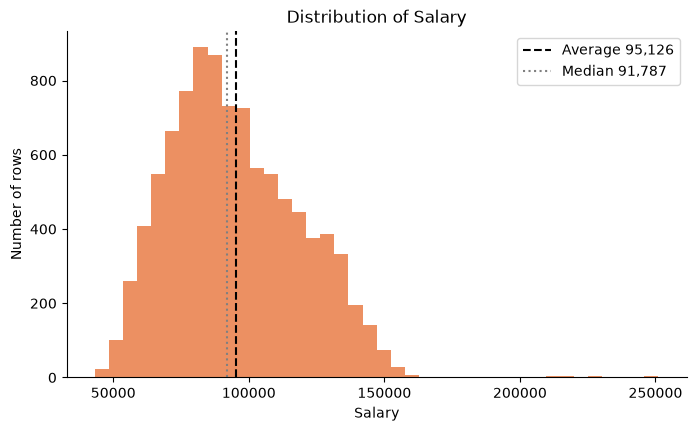

In [9]:
y_all = data[TARGET]
if CLASSIFICATION:
    shares = y_all.value_counts(normalize=True).sort_index() * 100
    plt.bar(["0", "1"], [shares.get(0, 0), shares.get(1, 0)], color=["grey", "#e8743b"])
    plt.ylabel("Share of rows (%)")
    print(f"{shares.get(1, 0):.1f}% of the rows are 1s. A model that always says 0 is right {shares.get(0, 0):.1f}% of the time.")
else:
    plt.hist(y_all, bins=40, color="#e8743b", alpha=0.8)
    plt.axvline(y_all.mean(), color="black", ls="--", label=f"Average {fmt(y_all.mean())}")
    plt.axvline(y_all.median(), color="grey", ls=":", label=f"Median {fmt(y_all.median())}")
    plt.ylabel("Number of rows")
    plt.legend()
    print(f"{TARGET} ranges from {fmt(y_all.min())} to {fmt(y_all.max())}; half the rows are between {fmt(y_all.quantile(0.25))} and {fmt(y_all.quantile(0.75))}.")
plt.title(f"Distribution of {TARGET}")
plt.xlabel(TARGET)
plt.show()

The next cell ranks every input by the strength of its link with the target (0 = none, 1 = perfect). It is a quick screen, not a model: it looks at one input at a time.

In [10]:
inputs = [c for c in data.columns if c != TARGET and data[c].nunique() > 1
          and not (is_text(data[c]) and data[c].nunique() > 0.9 * len(data))]
ranking = pd.Series({c: strength(data[c], data[TARGET]) for c in inputs}).sort_values(ascending=False)
print("Strength of each input's link with", TARGET)
display(ranking.round(3).to_frame("Strength (0 to 1)").T)

Strength of each input's link with Salary


,Job_Level,Years_Experience,Age,Department,Education_Level,Performance_Score,Region,Gender
Strength (0 to 1),0.824,0.809,0.745,0.345,0.25,0.117,0.066,0.02


In [11]:
# ✏️ Change this setting: how many inputs to chart
N_CHARTS = 6

The next cell draws one chart per top input and prints the fact it shows. Under each, the caption template helps you write the business sentence.

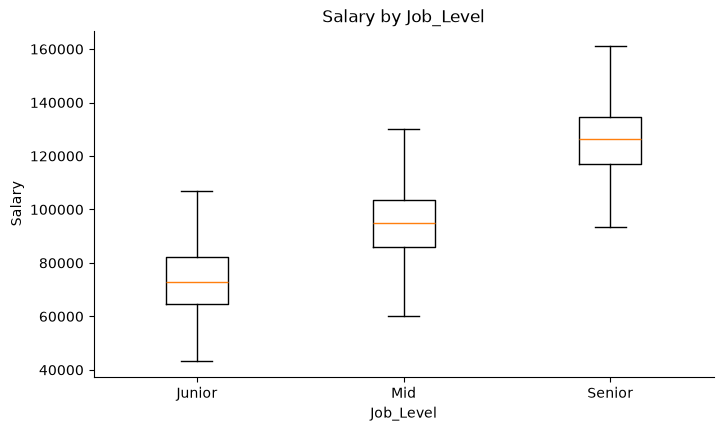

Fact: Highest average Salary: Job_Level = Senior (126,524); lowest: Junior (73,849).
Caption template: "Job_Level [matters / barely matters] for Salary: ____, which means ____ for the business."



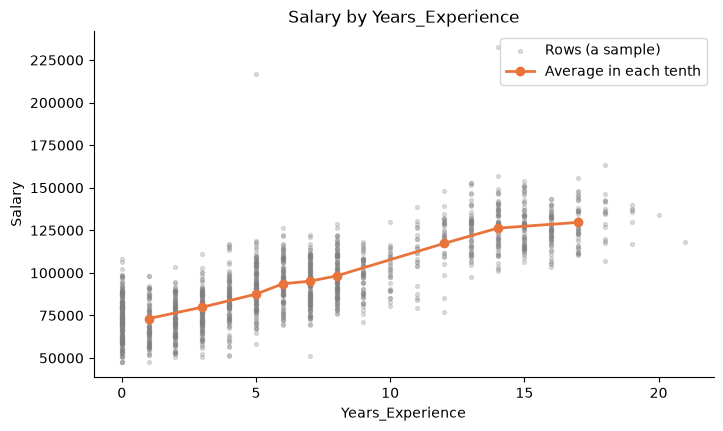

Fact: From the lowest to the highest tenth of Years_Experience, the average Salary goes from 73,156 to 129,667 (peak 129,667).
Caption template: "Years_Experience [matters / barely matters] for Salary: ____, which means ____ for the business."



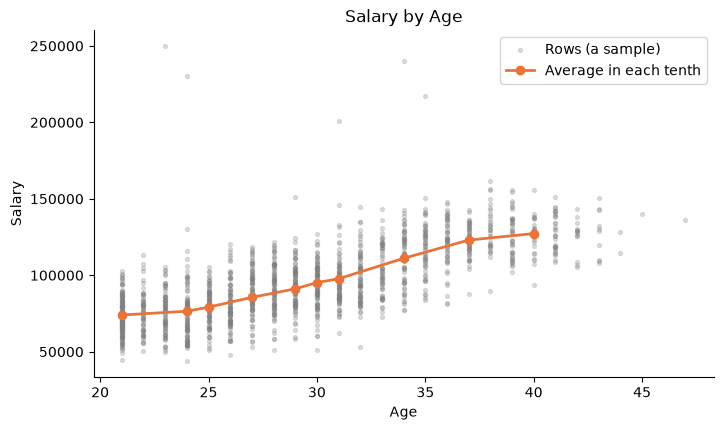

Fact: From the lowest to the highest tenth of Age, the average Salary goes from 74,008 to 127,252 (peak 127,252).
Caption template: "Age [matters / barely matters] for Salary: ____, which means ____ for the business."



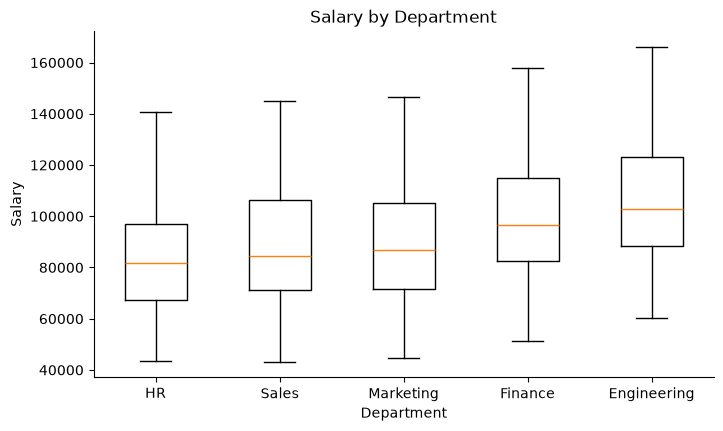

Fact: Highest average Salary: Department = Engineering (105,903); lowest: HR (84,313).
Caption template: "Department [matters / barely matters] for Salary: ____, which means ____ for the business."



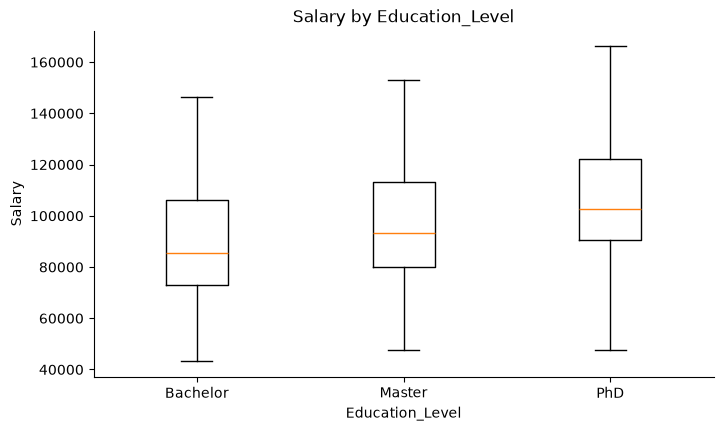

Fact: Highest average Salary: Education_Level = PhD (106,721); lowest: Bachelor (89,760).
Caption template: "Education_Level [matters / barely matters] for Salary: ____, which means ____ for the business."



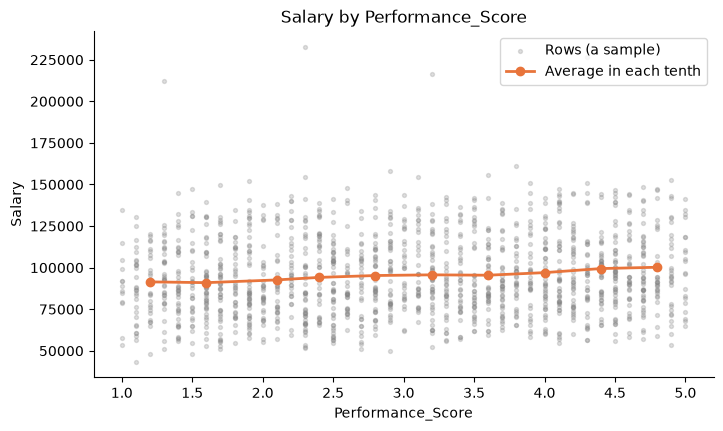

Fact: From the lowest to the highest tenth of Performance_Score, the average Salary goes from 91,436 to 100,232 (peak 100,232).
Caption template: "Performance_Score [matters / barely matters] for Salary: ____, which means ____ for the business."



In [12]:
for col in ranking.index[:N_CHARTS]:
    fact = chart_input(data, col, TARGET)
    print("Fact:", fact)
    print(f"Caption template: \"{col} [matters / barely matters] for {TARGET}: ____, which means ____ for the business.\"\n")

The next cell shows how the numeric columns move together. Values near +1 or −1 are strong links; two inputs that are strongly linked to each other carry almost the same information.

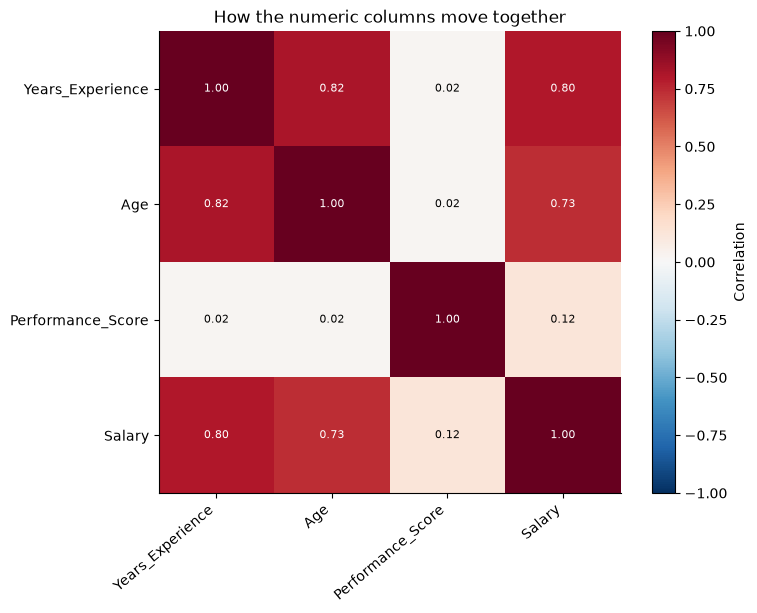

In [13]:
num = [c for c in ranking.index if not is_text(data[c])][:10]
if len(num) >= 1:
    corr = data[num + [TARGET]].astype(float).corr()
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
    ax.set_yticks(range(len(corr)), corr.columns)
    for i in range(len(corr)):
        for j in range(len(corr)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
    fig.colorbar(im, ax=ax, label="Correlation")
    ax.set_title("How the numeric columns move together")
    plt.show()
else:
    print("There are no numeric inputs to correlate.")

**✍️ Your interpretation.** _Write your three patterns, one sentence each, using the facts printed under the charts. Which one surprised you?_

## <span class="hz-step-n">05</span> Train/test split and baseline

A quarter of the rows is locked away as the **test set**: the models never see it while they learn, so it tells us how they will do on new cases ([week 3](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/)). The **baseline** is the answer you would give with no model at all; any model must beat it to be worth its cost.

<div class="hz-widget" data-widget="train-test-split">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/">open this page on the course website</a> to use it.</p>
</div>

The next cell splits the rows (keeping the same share of 1s in both parts for classification) and lists the inputs the models will use.

In [14]:
X, y = data.drop(columns=TARGET), data[TARGET]
NUM_COLS = [c for c in X.columns if not is_text(X[c]) and X[c].nunique() > 1]
CAT_COLS = [c for c in X.columns if is_text(X[c]) and 1 < X[c].nunique() <= 0.9 * len(X)]
X = X[NUM_COLS + CAT_COLS].copy()
for c in NUM_COLS:
    X[c] = X[c].astype(float)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y if CLASSIFICATION else None)
print(f"Training rows: {len(X_train):,}. Test rows: {len(X_test):,}.")
print(f"Numeric inputs ({len(NUM_COLS)}): {', '.join(NUM_COLS)}")
print(f"Text inputs ({len(CAT_COLS)}, up to 20 labels each): {', '.join(CAT_COLS)}")
skipped = [c for c in data.columns if c not in X.columns and c != TARGET]
if skipped:
    print("Not used (one value only, or looks like an identifier):", ", ".join(skipped))

Training rows: 7,194. Test rows: 2,399.
Numeric inputs (3): Years_Experience, Age, Performance_Score
Text inputs (5, up to 20 labels each): Education_Level, Department, Region, Job_Level, Gender


The next cell scores the baseline: the average of the training rows (regression) or the most common answer (classification).

In [15]:
baseline = (DummyClassifier(strategy="prior") if CLASSIFICATION else DummyRegressor()).fit(X_train, y_train)
display(score_table(baseline))
if CLASSIFICATION:
    print(f"Saying '{int(y_train.mode()[0])}' for everyone is right {skm.accuracy_score(y_test, baseline.predict(X_test)):.1%} of the time, "
          "but it never finds a single 1 (recall 0). AUC 0.5 means it cannot rank risk at all.")
else:
    print(f"Predicting {fmt(y_train.mean())} for everyone misses by {fmt(skm.mean_absolute_error(y_test, baseline.predict(X_test)))} on average (MAE). "
          "This is the error to beat.")

,MAE,RMSE,R²
Train,19611.77,24232.87,0.0
Test,19644.67,24149.55,-0.0


Predicting 94,933 for everyone misses by 19,645 on average (MAE). This is the error to beat.


**✍️ Your interpretation.** _In business terms, how big is the baseline's error? How much better would a model need to be to change a decision?_

## <span class="hz-step-n">06</span> Linear model

The first real model: a straight-line regression for a number ([week 3](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_3_Live/)) or a logistic regression for a yes/no ([week 4](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/)). Text inputs become 0/1 columns (one-hot encoding). Compare train and test: similar scores mean the model learned something general.

The next cell trains the model and prints its metrics on the training and test rows.

In [16]:
linear = make_pipeline(make_prep(scale=CLASSIFICATION, drop_first=True),
                       LogisticRegression(max_iter=2000) if CLASSIFICATION else LinearRegression())
linear.fit(X_train, y_train)
LINEAR_NAME = "Logistic regression" if CLASSIFICATION else "Linear regression"
display(score_table(linear))
if CLASSIFICATION:
    cm = skm.confusion_matrix(y_test, linear.predict(X_test))
    display(pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Predicted 0", "Predicted 1"]))
    print(f"With the usual 0.5 threshold, on the test rows it catches {cm[1, 1]:,} of the {cm[1].sum():,} real 1s "
          f"and raises {cm[0, 1]:,} false alarms.")
else:
    e = skm.mean_absolute_error(y_test, linear.predict(X_test))
    print(f"Typical error on new rows: {fmt(e)}, about {e / y_test.mean():.0%} of the average {TARGET}.")

,MAE,RMSE,R²
Train,4861.15,8989.04,0.86
Test,4692.20,8263.54,0.88


Typical error on new rows: 4,692, about 5% of the average Salary.


The next cell lists the ten inputs with the largest effect. For a number, the effect is that of a *typical change* (one standard deviation); for a label, it is the change compared with the label left out as the base (shown in the *Change* column).

In [17]:
prep, est = linear[0], linear[-1]
base = base_labels(prep)
coef = est.coef_[0] if CLASSIFICATION else est.coef_
sd = X_train[NUM_COLS].std().values
rows = []
for i, (n, b) in enumerate(zip(prep.get_feature_names_out(), coef)):
    n, is_num = nice_name(n), i < len(NUM_COLS)
    change = f"+{fmt(sd[i])} (a typical step)" if is_num else f"instead of {base[n.split(' = ')[0]]}"
    effect = b * sd[i] if is_num and not CLASSIFICATION else b
    rows.append({"Input": n, "Change": change, "Effect": effect})
coefs = pd.DataFrame(rows).assign(size=lambda d: d["Effect"].abs()).nlargest(10, "size").drop(columns="size")
coefs = coefs.reset_index(drop=True)
if CLASSIFICATION:
    coefs["Effect"] = np.exp(coefs["Effect"]).round(2)
    coefs = coefs.rename(columns={"Effect": "Odds of a 1 are multiplied by"})
else:
    coefs["Effect"] = coefs["Effect"].map(lambda v: f"{'+' if v >= 0 else ''}{fmt(v)}")
    coefs = coefs.rename(columns={"Effect": f"Change in predicted {TARGET}"})
display(coefs)

,Input,Change,Change in predicted Salary
0,Job_Level = Senior,instead of Junior,"+37,205"
1,Department = HR,instead of Engineering,"-19,401"
2,Education_Level = PhD,instead of Bachelor,"+17,116"
3,Department = Sales,instead of Engineering,"-16,343"
4,Job_Level = Mid,instead of Junior,"+15,704"
5,Department = Marketing,instead of Engineering,"-14,007"
6,Education_Level = Master,instead of Bachelor,"+7,620"
7,Years_Experience,+5.18 (a typical step),"+5,193"
8,Department = Finance,instead of Engineering,"-4,778"
9,Region = South,instead of East,"-3,255"


The next cell writes the first row of the table as a sentence, the way you would say it to a manager.

In [18]:
top = coefs.iloc[0]
if CLASSIFICATION:
    print(f"Read the first row like this: with {top['Input']} ({top['Change']}), other inputs fixed, the odds of a 1 are multiplied by "
          f"{top.iloc[2]:.2f}. Above 1 raises the risk; below 1 lowers it.")
else:
    print(f"Read the first row like this: with {top['Input']} ({top['Change']}), other inputs fixed, "
          f"the predicted {TARGET} changes by {top.iloc[2]}.")

Read the first row like this: with Job_Level = Senior (instead of Junior), other inputs fixed, the predicted Salary changes by +37,205.


**✍️ Your interpretation.** _Which effects make business sense, and which surprise you? Is any effect large enough to act on?_

## <span class="hz-step-n">07</span> Threshold by cost

**Classification only.** The model gives a probability; the business decides from which probability to act. The usual 0.5 is rarely the cheapest. Here every threshold is priced with your two costs on the test rows, using the logistic model ([week 4](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_4_Live/)). For regression, this section prints a note and you can skip it.

**Watch out:** choosing the threshold on the same test rows you report makes the saving look slightly better than it will be on new data. In your presentation, call it an estimate, as we did with Altamar in week 4.

<div class="hz-widget" data-widget="cost-threshold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/">open this page on the course website</a> to use it.</p>
</div>

The next cell prices every threshold, compares the cheapest one with 0.5, and draws the cost curve.

In [19]:
if CLASSIFICATION:
    curve = cost_curve(predict_score(linear, X_test), y_test.values)
    best_t = curve.loc[curve["Cost"].idxmin()]
    at_half = curve.loc[curve["Threshold"] == 0.5].iloc[0]
    display(pd.DataFrame([at_half, best_t], index=["Usual (0.5)", "Cheapest"]).astype({"Missed 1s (FN)": "int64", "False alarms (FP)": "int64", "Cost": "int64"}))
    print(f"Acting from a probability of {best_t['Threshold']:.2f} instead of 0.50 saves {CURRENCY} "
          f"{fmt(at_half['Cost'] - best_t['Cost'])} on these {len(y_test):,} test rows.")
    plt.plot(curve["Threshold"], curve["Cost"], color="#e8743b")
    plt.axvline(0.5, color="grey", ls="--", label="0.5")
    plt.axvline(best_t["Threshold"], color="black", ls=":", label=f"Cheapest: {best_t['Threshold']:.2f}")
    plt.title("Total cost of the mistakes at each threshold (test rows)")
    plt.xlabel("Threshold: act when the probability is at least this")
    plt.ylabel(f"Total cost ({CURRENCY})")
    plt.legend()
    plt.show()
else:
    print("This is a regression task: there is no threshold to choose. Go on to section 08.")

This is a regression task: there is no threshold to choose. Go on to section 08.


**✍️ Your interpretation.** _Which threshold would you recommend and why? What would the business do differently with it? How sure are you of the two costs?_

## <span class="hz-step-n">08</span> Decision tree with cross-validation

A tree asks yes/no questions and can bend where a line cannot. Its depth decides how detailed it gets: too shallow misses patterns, too deep memorises the training rows. **Cross-validation** tries depths 2 to 10 on five different slices of the training rows and picks the depth that does best on rows it did not learn from ([week 5](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_5_Live/)).

<div class="hz-widget" data-widget="kfold">
<p>▶ Interactive simulator: <a href="https://hizocar.github.io/mba-business-analytics-1/case/Case_Toolkit/">open this page on the course website</a> to use it.</p>
</div>

The next cell runs the cross-validation (45 small trees) and draws the training score against the validation score for each depth.

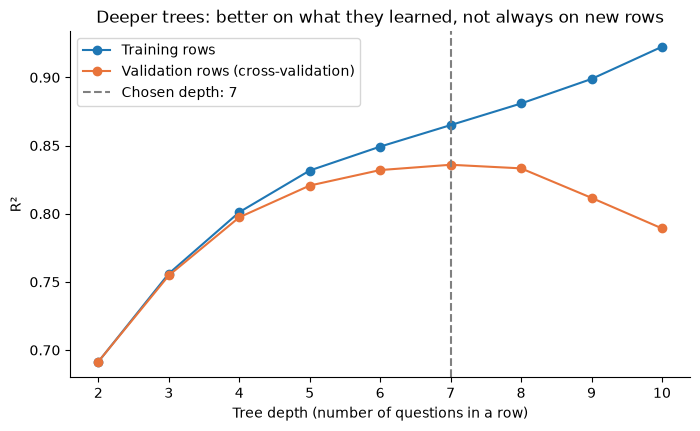

Chosen depth: 7 (validation R² 0.836).


In [20]:
SCORING = "roc_auc" if CLASSIFICATION else "r2"
folds = (StratifiedKFold if CLASSIFICATION else KFold)(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Tree = DecisionTreeClassifier if CLASSIFICATION else DecisionTreeRegressor
cv_rows = []
for depth in range(2, 11):
    r = cross_validate(make_pipeline(make_prep(), Tree(max_depth=depth, random_state=RANDOM_STATE)),
                       X_train, y_train, cv=folds, scoring=SCORING, return_train_score=True)
    cv_rows.append({"Depth": depth, "Train": r["train_score"].mean(), "Validation": r["test_score"].mean()})
cv_table = pd.DataFrame(cv_rows).set_index("Depth")
BEST_DEPTH = int(cv_table["Validation"].idxmax())
plt.plot(cv_table.index, cv_table["Train"], marker="o", label="Training rows")
plt.plot(cv_table.index, cv_table["Validation"], marker="o", color="#e8743b", label="Validation rows (cross-validation)")
plt.axvline(BEST_DEPTH, color="grey", ls="--", label=f"Chosen depth: {BEST_DEPTH}")
plt.title("Deeper trees: better on what they learned, not always on new rows")
plt.xlabel("Tree depth (number of questions in a row)")
plt.ylabel("AUC" if CLASSIFICATION else "R²")
plt.legend()
plt.show()
print(f"Chosen depth: {BEST_DEPTH} (validation {'AUC' if CLASSIFICATION else 'R²'} {cv_table['Validation'].max():.3f}).")

The next cell trains the tree at the chosen depth on all the training rows and scores it on the test rows.

In [21]:
tree = make_pipeline(make_prep(), Tree(max_depth=BEST_DEPTH, random_state=RANDOM_STATE)).fit(X_train, y_train)
display(score_table(tree))

,MAE,RMSE,R²
Train,5306.35,9084.89,0.86
Test,5678.67,9604.79,0.84


The next cell draws the first three levels of the tree. Each box shows the question, how many training rows reach it, and the prediction there (the average, or the share of 0s and 1s). A question such as *Department = HR <= 0.5* means "is the department something other than HR?": *True* goes left.

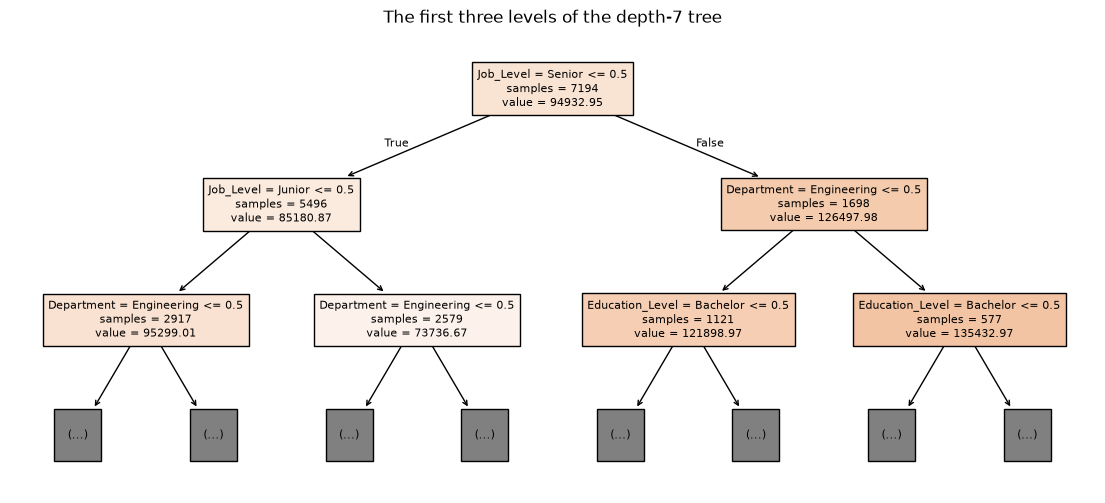

In [22]:
fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree[-1], max_depth=2, feature_names=[nice_name(n) for n in tree[0].get_feature_names_out()],
          filled=True, impurity=False, proportion=CLASSIFICATION, precision=2, fontsize=8, ax=ax)
ax.set_title(f"The first three levels of the depth-{BEST_DEPTH} tree")
plt.show()

**✍️ Your interpretation.** _Read the first two questions the tree asks. Do they match the patterns of section 04? Did the tree beat the linear model on the test rows?_

## <span class="hz-step-n">09</span> Random forest and gradient boosting

Two ways to combine many trees ([week 6](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/)). A **random forest** averages a hundred trees, each grown on a different sample of rows. **Gradient boosting** grows trees one after another, each fixing the errors of the ones before. They are usually the most accurate, and harder to explain.

The next cell trains the random forest and prints its metrics. A big gap between train and test is normal for forests; judge it by the test row.

In [23]:
Forest = RandomForestClassifier if CLASSIFICATION else RandomForestRegressor
forest = make_pipeline(make_prep(), Forest(n_estimators=100, min_samples_leaf=3, max_features=0.5,
                                           random_state=RANDOM_STATE)).fit(X_train, y_train)
display(score_table(forest))

,MAE,RMSE,R²
Train,3703.40,7107.21,0.91
Test,5019.28,8525.51,0.88


The next cell trains gradient boosting and prints its metrics.

In [24]:
Boost = HistGradientBoostingClassifier if CLASSIFICATION else HistGradientBoostingRegressor
boost = make_pipeline(make_prep(), Boost(random_state=RANDOM_STATE)).fit(X_train, y_train)
display(score_table(boost))

,MAE,RMSE,R²
Train,4455.60,7933.30,0.89
Test,5000.65,8489.59,0.88


**✍️ Your interpretation.** _How much do the two ensembles gain over the single tree and the linear model? Is the gain worth losing a model you can draw?_

## <span class="hz-step-n">10</span> Scoreboard

Every model on the same test rows, in one table ([week 6](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/)). The best one is marked. For regression, look at the error in your units (MAE) and R²; for classification, AUC ranks risk and the cost column prices each model at its own cheapest threshold.

The next cell builds the table and, for classification, draws the ROC curves together.

In [25]:
models = {"Baseline": baseline, LINEAR_NAME: linear, f"Decision tree (depth {BEST_DEPTH})": tree,
          "Random forest": forest, "Gradient boosting": boost}
board = pd.DataFrame({name: scores(m, X_test, y_test) for name, m in models.items()}).T
if CLASSIFICATION:
    costs = {name: cost_curve(predict_score(m, X_test), y_test.values) for name, m in models.items()}
    board[f"Lowest cost ({CURRENCY})"] = [int(c["Cost"].min()) for c in costs.values()]
    board["at threshold"] = [c.loc[c["Cost"].idxmin(), "Threshold"] for c in costs.values()]
key = "AUC" if CLASSIFICATION else "R²"
BEST_NAME = board.drop(index="Baseline")[key].idxmax()
board[""] = ["◀ best" if n == BEST_NAME else "" for n in board.index]
display(board.round(3) if CLASSIFICATION else board.round({"MAE": 1, "RMSE": 1, "R²": 3}))
print(f"Best on the test rows by {key}: {BEST_NAME}.")
if CLASSIFICATION:
    for name, m in models.items():
        fpr, tpr, _ = skm.roc_curve(y_test, predict_score(m, X_test))
        plt.plot(fpr, tpr, label=f"{name} (AUC {board.loc[name, 'AUC']:.2f})", lw=2.5 if name == BEST_NAME else 1.2)
    plt.title("ROC curves on the test rows: higher and to the left is better")
    plt.xlabel("Share of 0s wrongly flagged (false alarms)")
    plt.ylabel("Share of 1s caught")
    plt.legend()
    plt.show()

,MAE,RMSE,R²,
Baseline,19644.7,24149.6,-0.001,
Linear regression,4692.2,8263.5,0.883,◀ best
Decision tree (depth 7),5678.7,9604.8,0.842,
Random forest,5019.3,8525.5,0.875,
Gradient boosting,5000.7,8489.6,0.876,


Best on the test rows by R²: Linear regression.


**✍️ Your interpretation.** _Which model do you recommend, and why: accuracy, cost, simplicity, or how easy it is to explain? Would a manager trust it?_

## <span class="hz-step-n">11</span> What drives the predictions

Two views of the best model ([week 6](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/)). **Permutation importance** shuffles one input at a time on the test rows and measures how much worse the model gets: the bigger the drop, the more the model relies on that input. **Partial dependence** shows how the prediction moves, on average, as one number changes.

The next cell computes the permutation importance of the best model (three shuffles per input) and draws it.

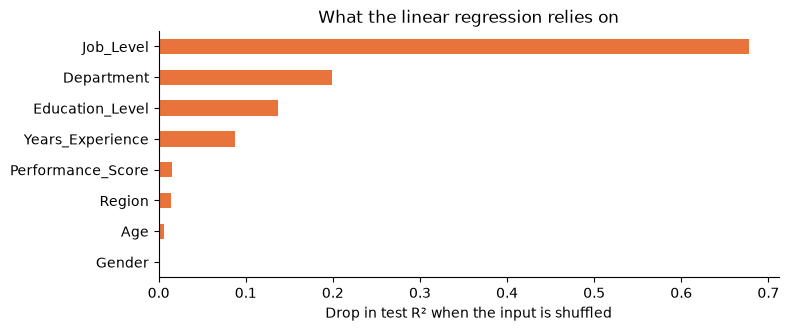

Top three: Job_Level (0.678), Department (0.199), Education_Level (0.137)


In [26]:
best = models[BEST_NAME]
sample = X_test.sample(min(1500, len(X_test)), random_state=RANDOM_STATE)
imp = permutation_importance(best, sample, y_test.loc[sample.index], scoring=SCORING,
                             n_repeats=3, random_state=RANDOM_STATE)
importance = pd.Series(imp.importances_mean, index=sample.columns).sort_values()
importance.tail(12).plot.barh(color="#e8743b", figsize=(8, max(3, 0.4 * min(12, len(importance)))))
plt.title(f"What the {BEST_NAME.lower()} relies on")
plt.xlabel(f"Drop in test {'AUC' if CLASSIFICATION else 'R²'} when the input is shuffled")
plt.ylabel("")
plt.show()
print("Top three:", ", ".join(f"{c} ({v:.3f})" for c, v in importance.sort_values(ascending=False).head(3).items()))

The next cell draws the partial dependence curves of the three most important numeric inputs: the average prediction as each one moves, the others fixed.

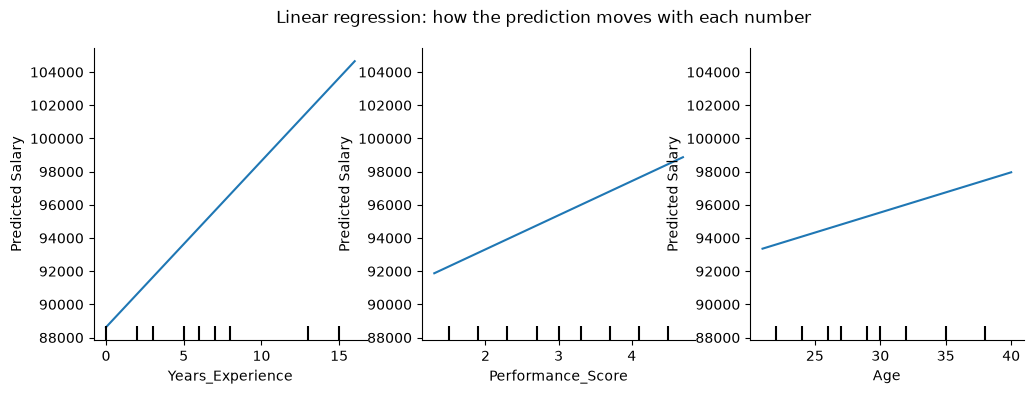

In [27]:
top_num = [c for c in importance.sort_values(ascending=False).index if c in NUM_COLS and X_train[c].nunique() > 2][:3]
if top_num:
    pdp_rows = sample.copy()
    pdp_rows[NUM_COLS] = pdp_rows[NUM_COLS].fillna(X_train[NUM_COLS].median())
    for c in CAT_COLS:
        pdp_rows[c] = pdp_rows[c].fillna(X_train[c].mode()[0])
    fig, axes = plt.subplots(1, len(top_num), figsize=(4 * len(top_num), 3.8), squeeze=False)
    PartialDependenceDisplay.from_estimator(best, pdp_rows.head(800), top_num, grid_resolution=20, ax=axes[0])
    for a in fig.axes:
        a.set_ylabel("Probability of a 1" if CLASSIFICATION else f"Predicted {TARGET}")
    fig.suptitle(f"{BEST_NAME}: how the prediction moves with each number")
    plt.show()
else:
    print("There are no numeric inputs with more than two values to draw.")

**✍️ Your interpretation.** _Explain the top three drivers in plain words. Is each curve a straight line, or does it bend? What would you do differently because of it?_

## <span class="hz-step-n">12</span> Your conclusions

Fill in this checklist before you build the slides. It follows the rubric of the [case brief](https://hizocar.github.io/mba-business-analytics-1/case/case/), so each item is worth points. Lead the presentation with the answer, then the arguments, then the evidence ([the pyramid, week 6](https://hizocar.github.io/mba-business-analytics-1/sessions/Session_6_Live/)).

**Business framing (15%)**

☐ **The business question, in two lines.** _Write it here._

☐ **Who uses the answer, and which decision it changes.** _Write it here._

**Data and patterns (20%)**

☐ **The problems you fixed and why.** _Point to the cleaning log in section 03 and justify the two biggest decisions._

☐ **Three findings, each with its chart from section 04.** _1. … 2. … 3. …_

**Models and evaluation (25%)**

☐ **The recommended model and why.** _Name it, give its test metric next to the baseline's, and say why that metric fits the decision (for classification: the threshold and its cost)._

**Interpretation and recommendations (25%)**

☐ **What drives the predictions.** _The top drivers from section 11, in business words._

☐ **Three recommendations.** _Concrete enough to act on: who does what, and what it is worth._

☐ **Limitations.** _What the data cannot tell you, what could make the model wrong next year, and what you would check next._

**Communication (15%)**

☐ **The slides lead with the answer** and use only the few charts that carry it (10 slides at most).